# Customer Cohort & Churn Analytics: IBM Telco Dataset

**Datheon Data Analytics & Power BI Internship, Task 3**

**Goal:** segment customers by tenure cohort, contract type, payment method and service tier, quantify what drives churn, and recommend how to retain the highest-risk customers.

**Business questions**
1. What is the baseline churn rate, and how much recurring revenue does it cost?
2. Which customer attributes are most associated with churn?
3. How does retention decay over a customer's lifetime, by contract and service tier?
4. Which segments are highest-risk, and how much of the problem do they explain?

**Contents:** 1. Load and inspect, 2. Data quality, 3. Cleaning, 4. Baseline churn, 5. Churn drivers, 6. Tenure cohorts and retention matrix, 7. Retention curves, 8. High-risk segments, 9. Takeaways and recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
Path("images").mkdir(exist_ok=True)

pct0 = mtick.PercentFormatter(1.0, decimals=0)
DATA_PATH = "data/telco_customer_churn.csv"

## 1. Load and inspect

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head(3).T

Shape: (7043, 21)


,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


In [3]:
print("Columns with nulls:", int((df_raw.isna().sum() > 0).sum()))
df_raw.dtypes.to_frame("dtype").T

Columns with nulls: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,...,str,str,str,str,str,str,str,float64,str,str


## 2. Data quality
No nulls were reported, but `TotalCharges` is stored as text, which usually means some values are not numeric.

In [4]:
total_num = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
bad = df_raw[total_num.isna()]
print("TotalCharges values that are not numbers:", len(bad))
print("Their tenure values:", [int(t) for t in sorted(bad["tenure"].unique())])
print("Any of them churned?", (bad["Churn"] == "Yes").any())
bad[["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]].head(5)

TotalCharges values that are not numbers: 11
Their tenure values: [0]
Any of them churned? False


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No


**Finding:** the 11 blank `TotalCharges` values are all customers with **tenure = 0**, meaning brand-new customers who have not been billed yet, and none of them churned. They are not errors, so I keep them and set `TotalCharges` to 0 instead of dropping them.

## 3. Data cleaning and feature engineering

In [5]:
df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churned"] = (df["Churn"] == "Yes").astype(int)
df["Senior"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# tenure cohorts (months with the company)
df["Tenure Cohort"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 36, 48, 60, 72],
                             labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"])

# monthly charge bands
df["Charge Band"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 55, 75, 95, 120],
                           labels=["<=$35", "$35-55", "$55-75", "$75-95", "$95+"])

# service tier: internet type combined with tech support
def service_tier(row):
    if row["InternetService"] == "No":
        return "No internet"
    support = "tech support" if row["TechSupport"] == "Yes" else "no tech support"
    return f"{row['InternetService']}, {support}"

df["Service Tier"] = df.apply(service_tier, axis=1)
df["Service Tier"].value_counts().to_frame("Customers")

,Customers
Service Tier,
"Fiber optic, no tech support",2230
No internet,1526
"DSL, no tech support",1243
"DSL, tech support",1178
"Fiber optic, tech support",866


In [6]:
assert df["customerID"].is_unique, "duplicate customers"
assert df.isna().sum().sum() == 0, "unexpected nulls"
assert df["tenure"].between(0, 72).all()
assert set(df["Churn"].unique()) == {"Yes", "No"}
assert (df["TotalCharges"] >= 0).all()
print(f"Clean dataset: {len(df):,} customers, {df.shape[1]} columns. All validation checks passed")

Clean dataset: 7,043 customers, 26 columns. All validation checks passed


## 4. Baseline churn and revenue at risk

In [7]:
n_customers = len(df)
n_churned = int(df["Churned"].sum())
baseline = df["Churned"].mean()
mrr_total = df["MonthlyCharges"].sum()
mrr_lost = df.loc[df["Churned"] == 1, "MonthlyCharges"].sum()

print(f"Customers          : {n_customers:,}")
print(f"Churned            : {n_churned:,}")
print(f"Baseline churn rate: {baseline:.1%}")
print(f"Monthly revenue    : ${mrr_total:,.0f}")
print(f"Monthly revenue lost to churners: ${mrr_lost:,.0f} ({mrr_lost/mrr_total:.1%})")

profile = df.groupby("Churn").agg(Customers=("customerID", "size"),
                                  Avg_Monthly_Charge=("MonthlyCharges", "mean"),
                                  Median_Tenure_Months=("tenure", "median"))
profile.style.format({"Avg_Monthly_Charge": "${:,.2f}", "Median_Tenure_Months": "{:.0f}"})

Customers          : 7,043
Churned            : 1,869
Baseline churn rate: 26.5%
Monthly revenue    : $456,117
Monthly revenue lost to churners: $139,131 (30.5%)


,Customers,Avg_Monthly_Charge,Median_Tenure_Months
Churn,,,
No,5174,$61.27,38
Yes,1869,$74.44,10


## 5. Churn drivers
Churn rate for each group, compared with the baseline (red dashed line).

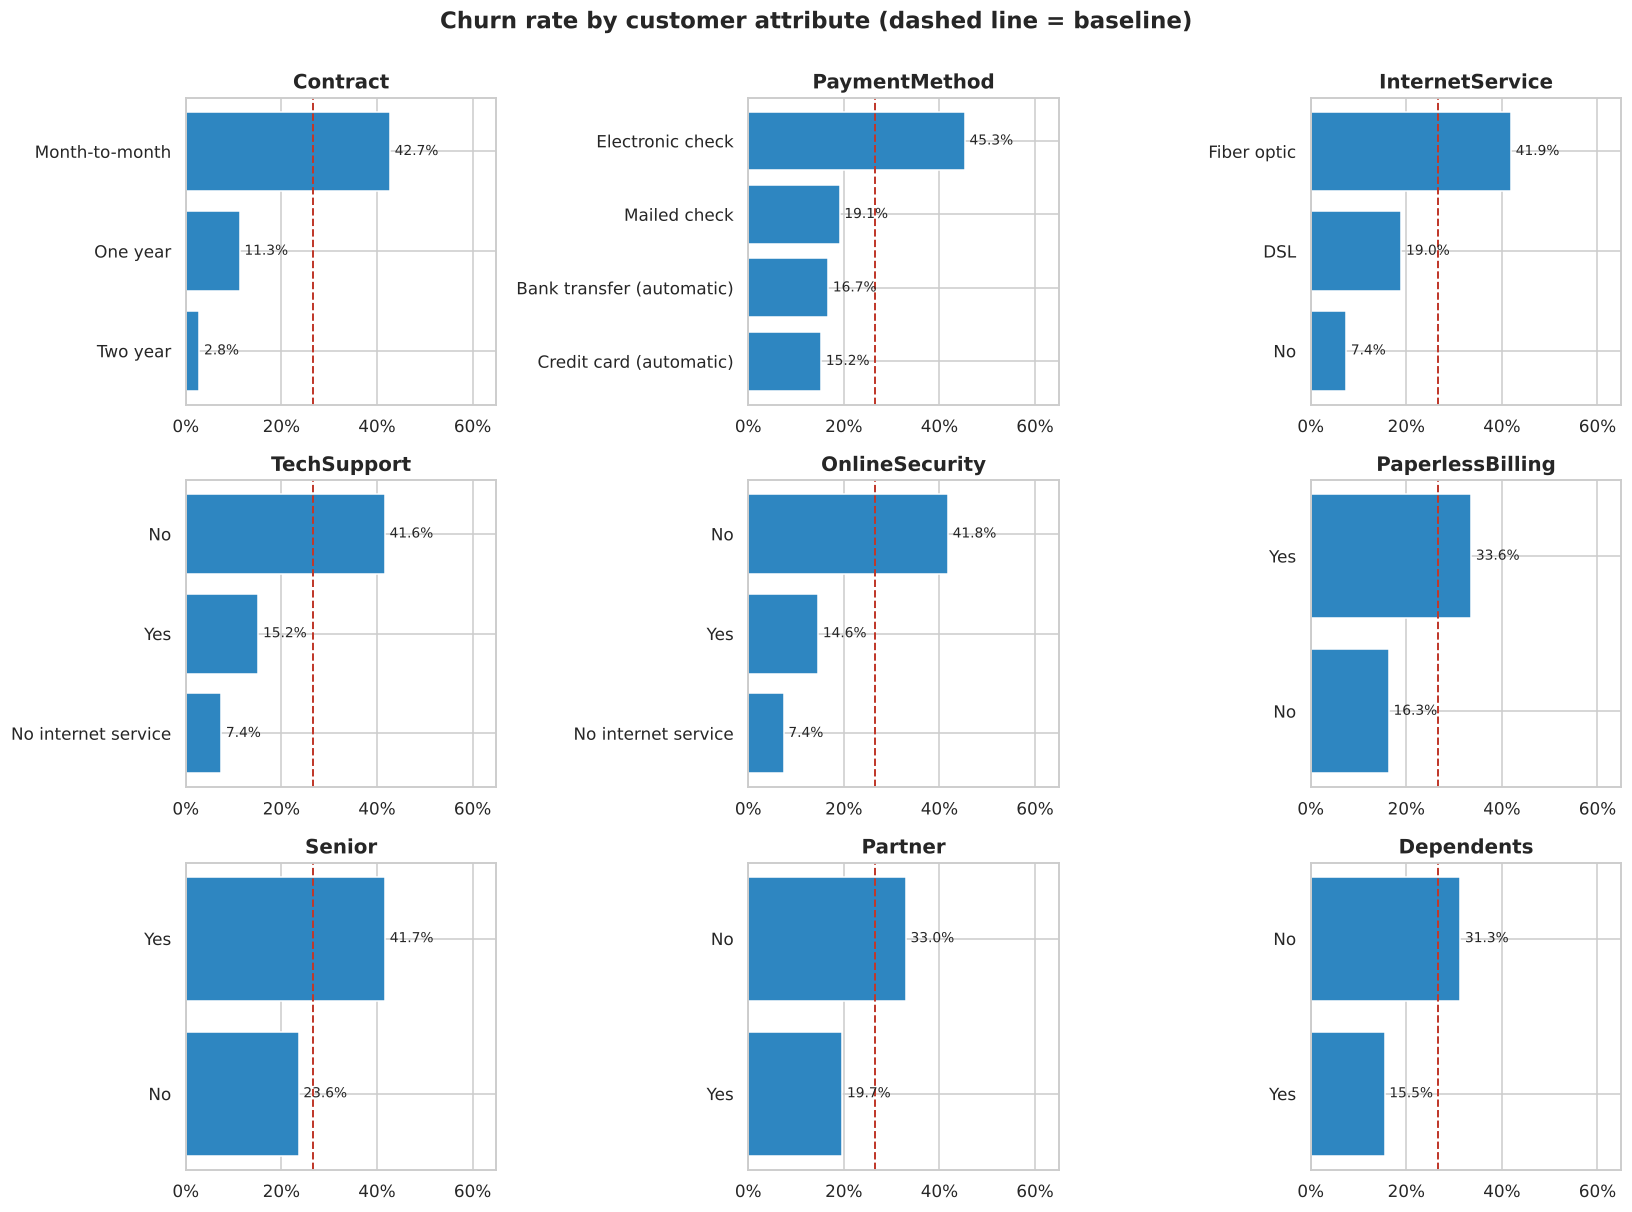

In [8]:
drivers = ["Contract", "PaymentMethod", "InternetService", "TechSupport", "OnlineSecurity",
           "PaperlessBilling", "Senior", "Partner", "Dependents"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), drivers):
    g = df.groupby(col)["Churned"].mean().sort_values()
    ax.barh(g.index.astype(str), g.values, color="#2e86c1")
    ax.axvline(baseline, color="#c0392b", ls="--", lw=1.3)
    for y, v in enumerate(g.values):
        ax.text(v + 0.01, y, f"{v:.1%}", va="center", fontsize=9)
    ax.set_xlim(0, 0.65)
    ax.xaxis.set_major_formatter(pct0)
    ax.set_title(col)
plt.suptitle("Churn rate by customer attribute (dashed line = baseline)", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); plt.savefig("images/01_churn_drivers.png", bbox_inches="tight"); plt.show()

### Which attributes separate churners from loyal customers the most?
For each attribute I take the gap between its highest-churn and lowest-churn group. This is descriptive only. Attributes tied to internet service look inflated because the "No internet service" group churns very little.

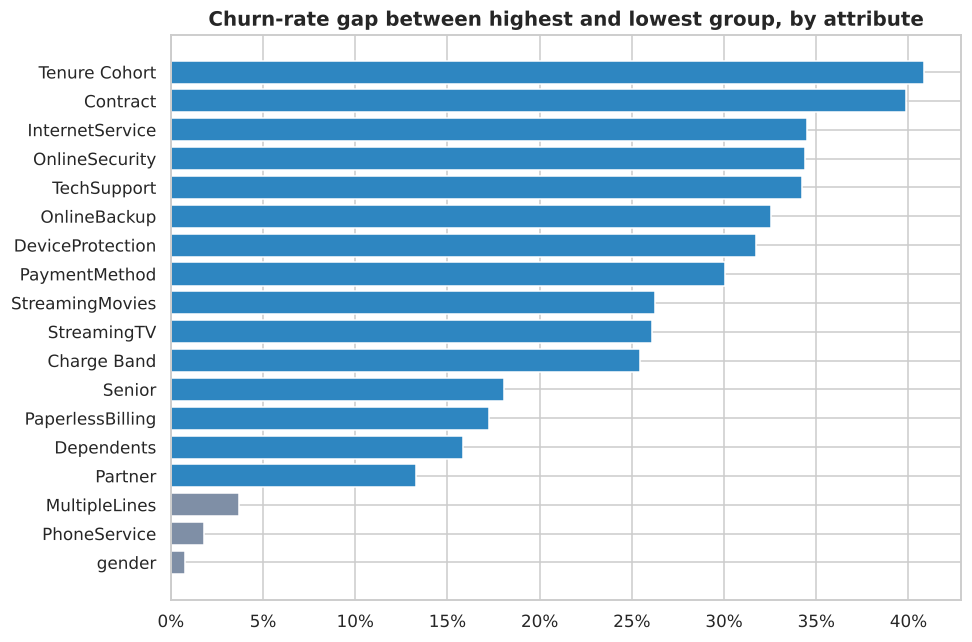

,Attribute,Highest group,Highest churn,Lowest group,Lowest churn,Gap
0,Tenure Cohort,0-12,47.4%,61-72,6.6%,40.8%
1,Contract,Month-to-month,42.7%,Two year,2.8%,39.9%
2,InternetService,Fiber optic,41.9%,No,7.4%,34.5%
3,OnlineSecurity,No,41.8%,No internet service,7.4%,34.4%
4,TechSupport,No,41.6%,No internet service,7.4%,34.2%
5,OnlineBackup,No,39.9%,No internet service,7.4%,32.5%
6,DeviceProtection,No,39.1%,No internet service,7.4%,31.7%
7,PaymentMethod,Electronic check,45.3%,Credit card (automatic),15.2%,30.0%
8,StreamingMovies,No,33.7%,No internet service,7.4%,26.3%
9,StreamingTV,No,33.5%,No internet service,7.4%,26.1%


In [9]:
attrs = ["gender", "Senior", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
         "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
         "Contract", "PaperlessBilling", "PaymentMethod", "Tenure Cohort", "Charge Band"]

rows = []
for a in attrs:
    g = df.groupby(a, observed=True)["Churned"].mean()
    rows.append({"Attribute": a, "Highest group": g.idxmax(), "Highest churn": g.max(),
                 "Lowest group": g.idxmin(), "Lowest churn": g.min(), "Gap": g.max() - g.min()})
gap = pd.DataFrame(rows).sort_values("Gap", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
plot = gap.sort_values("Gap")
ax.barh(plot["Attribute"], plot["Gap"], color=["#7f8fa6" if g < 0.1 else "#2e86c1" for g in plot["Gap"]])
ax.xaxis.set_major_formatter(pct0)
ax.set_title("Churn-rate gap between highest and lowest group, by attribute")
plt.tight_layout(); plt.savefig("images/02_driver_gap_ranking.png"); plt.show()

gap.style.format({"Highest churn": "{:.1%}", "Lowest churn": "{:.1%}", "Gap": "{:.1%}"})

### Monthly charges

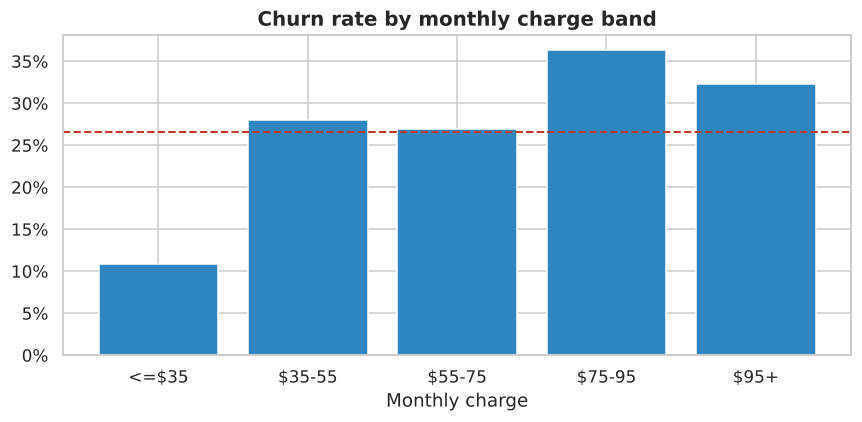

,Customers,Churn_Rate
Charge Band,,
<=$35,1735,10.9%
$35-55,897,28.0%
$55-75,1291,27.0%
$75-95,1825,36.3%
$95+,1295,32.3%


In [10]:
band = df.groupby("Charge Band", observed=True)["Churned"].agg(Customers="size", Churn_Rate="mean")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(band.index.astype(str), band["Churn_Rate"], color="#2e86c1")
ax.axhline(baseline, color="#c0392b", ls="--", lw=1.3)
ax.yaxis.set_major_formatter(pct0)
ax.set_title("Churn rate by monthly charge band"); ax.set_xlabel("Monthly charge")
plt.tight_layout(); plt.savefig("images/03_charge_band.png"); plt.show()
band.style.format({"Churn_Rate": "{:.1%}"})

## 6. Tenure cohorts and the retention matrix
The dataset has no sign-up dates, so a **cohort** here means the band of months a customer has been with the company (their tenure). Each cell below is the share of customers in that band who have **not** churned.

In [11]:
cohort = df.groupby("Tenure Cohort", observed=True)["Churned"].agg(Customers="size", Churn_Rate="mean")
print(f"Customers who churned within their first 12 months of tenure: "
      f"{int(((df['Churned'] == 1) & (df['tenure'] <= 12)).sum()):,} of {n_churned:,} churners "
      f"({((df['Churned'] == 1) & (df['tenure'] <= 12)).sum() / n_churned:.1%})")
cohort.style.format({"Churn_Rate": "{:.1%}"})

Customers who churned within their first 12 months of tenure: 1,037 of 1,869 churners (55.5%)


,Customers,Churn_Rate
Tenure Cohort,,
0-12,2186,47.4%
13-24,1024,28.7%
25-36,832,21.6%
37-48,762,19.0%
49-60,832,14.4%
61-72,1407,6.6%


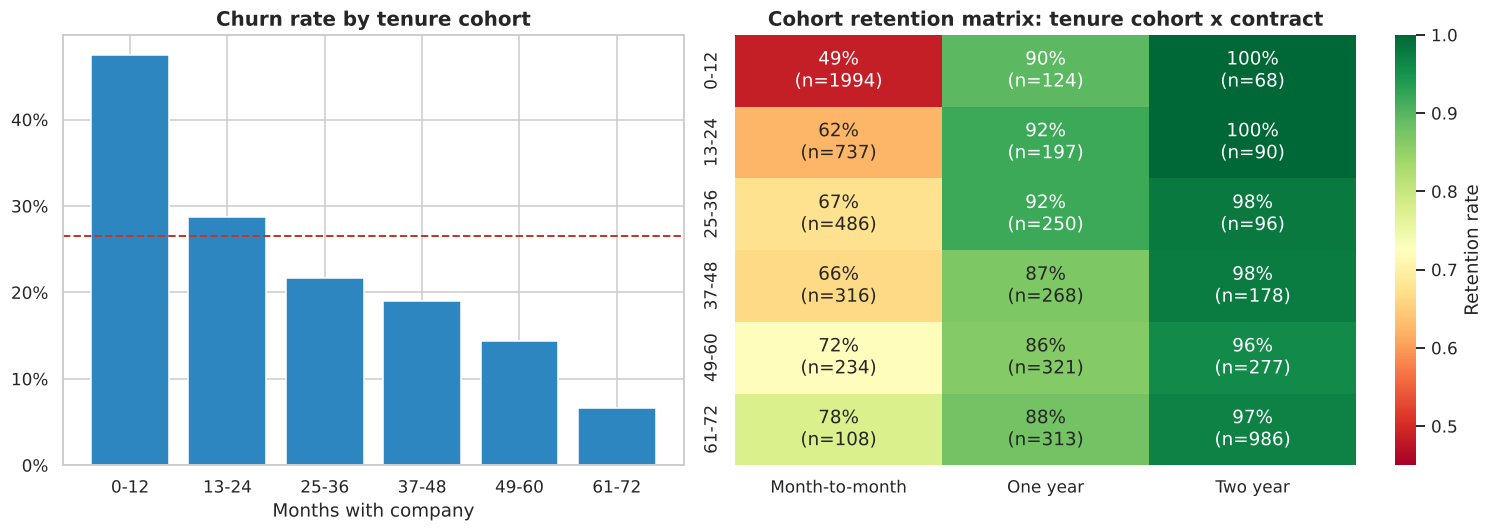

In [12]:
order = ["Month-to-month", "One year", "Two year"]
retention = 1 - df.pivot_table(index="Tenure Cohort", columns="Contract", values="Churned", aggfunc="mean", observed=True)[order]
counts = df.pivot_table(index="Tenure Cohort", columns="Contract", values="Churned", aggfunc="size", observed=True)[order]

annot = np.array([[f"{retention.iloc[i, j]:.0%}\n(n={counts.iloc[i, j]})" for j in range(retention.shape[1])]
                  for i in range(retention.shape[0])])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].bar(cohort.index.astype(str), cohort["Churn_Rate"], color="#2e86c1")
axes[0].axhline(baseline, color="#c0392b", ls="--", lw=1.3)
axes[0].yaxis.set_major_formatter(pct0)
axes[0].set_title("Churn rate by tenure cohort"); axes[0].set_xlabel("Months with company")

sns.heatmap(retention, annot=annot, fmt="", cmap="RdYlGn", vmin=0.45, vmax=1.0,
            cbar_kws={"label": "Retention rate"}, ax=axes[1])
axes[1].set_title("Cohort retention matrix: tenure cohort x contract")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig("images/04_cohort_retention_matrix.png"); plt.show()

## 7. Retention curves
A retention curve shows what share of customers is still active after *t* months. I use a **Kaplan-Meier style estimate**: at each tenure month, the survival probability is multiplied by `1 - churners / customers still at risk`. Customers who have not churned are treated as still active (censored) at their current tenure.

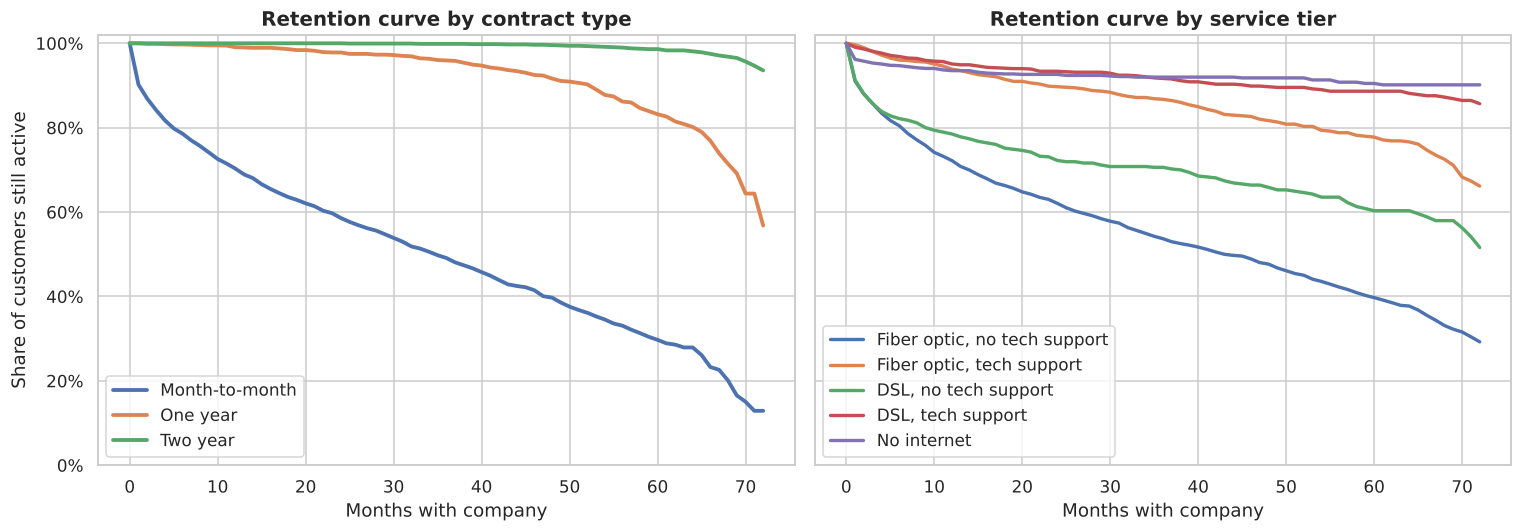

In [13]:
def retention_curve(d):
    events = d[d["Churned"] == 1].groupby("tenure").size()
    s, out = 1.0, {0: 1.0}
    for t in range(1, 73):
        at_risk = (d["tenure"] >= t).sum()
        if at_risk > 0:
            s *= 1 - events.get(t, 0) / at_risk
        out[t] = s
    return pd.Series(out)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for name in order:
    axes[0].plot(retention_curve(df[df["Contract"] == name]), lw=2.5, label=name)
axes[0].set_title("Retention curve by contract type")

tier_order = ["Fiber optic, no tech support", "Fiber optic, tech support", "DSL, no tech support",
              "DSL, tech support", "No internet"]
for name in tier_order:
    axes[1].plot(retention_curve(df[df["Service Tier"] == name]), lw=2.2, label=name)
axes[1].set_title("Retention curve by service tier")

for ax in axes:
    ax.set_xlabel("Months with company"); ax.yaxis.set_major_formatter(pct0)
    ax.set_ylim(0, 1.02); ax.legend(loc="lower left")
axes[0].set_ylabel("Share of customers still active")
plt.tight_layout(); plt.savefig("images/05_retention_curves.png"); plt.show()

In [14]:
checkpoints = [6, 12, 24, 36, 48]
curve_table = pd.DataFrame({name: retention_curve(df[df["Contract"] == name]).loc[checkpoints] for name in order})
curve_table.index = [f"{m} months" for m in checkpoints]
curve_table.style.format("{:.1%}")

,Month-to-month,One year,Two year
6 months,78.6%,99.7%,100.0%
12 months,70.3%,99.1%,100.0%
24 months,58.6%,97.8%,100.0%
36 months,49.1%,95.9%,99.9%
48 months,39.7%,91.7%,99.6%


## 8. High-risk segments
### Churn by service tier and contract
Cells with fewer than 30 customers are left blank because their rates are not reliable.

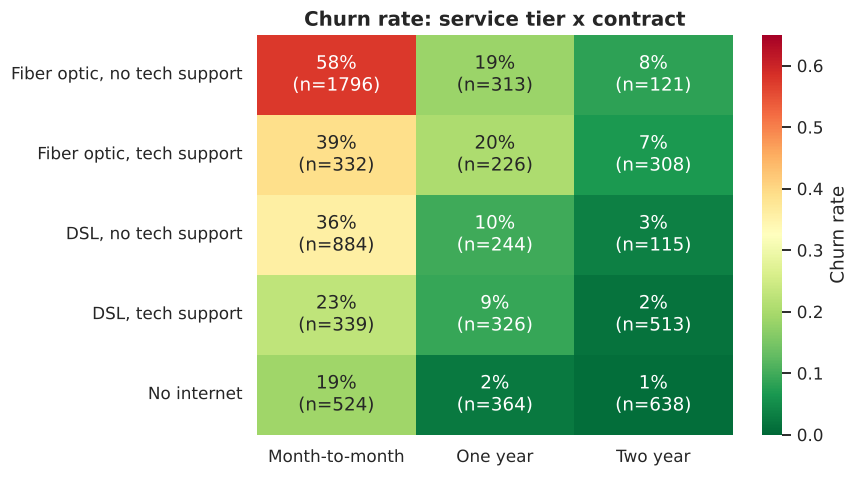

In [15]:
def masked_heatmap(index, columns, ax, title):
    rate = df.pivot_table(index=index, columns=columns, values="Churned", aggfunc="mean", observed=True)
    size = df.pivot_table(index=index, columns=columns, values="Churned", aggfunc="size", observed=True)
    rate = rate.where(size >= 30)
    labels = np.array([[("" if pd.isna(rate.iloc[i, j]) else f"{rate.iloc[i, j]:.0%}\n(n={size.iloc[i, j]})")
                        for j in range(rate.shape[1])] for i in range(rate.shape[0])])
    sns.heatmap(rate, annot=labels, fmt="", cmap="RdYlGn_r", vmin=0, vmax=0.65,
                cbar_kws={"label": "Churn rate"}, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")

fig, ax = plt.subplots(figsize=(8, 4.5))
tier_df = df.assign(Contract=pd.Categorical(df["Contract"], categories=order, ordered=True))
tier_df["Service Tier"] = pd.Categorical(tier_df["Service Tier"], categories=tier_order, ordered=True)
rate = tier_df.pivot_table(index="Service Tier", columns="Contract", values="Churned", aggfunc="mean", observed=False)
size = tier_df.pivot_table(index="Service Tier", columns="Contract", values="Churned", aggfunc="size", observed=False)
rate = rate.where(size >= 30)
labels = np.array([[("" if pd.isna(rate.iloc[i, j]) else f"{rate.iloc[i, j]:.0%}\n(n={int(size.iloc[i, j])})")
                    for j in range(rate.shape[1])] for i in range(rate.shape[0])])
sns.heatmap(rate, annot=labels, fmt="", cmap="RdYlGn_r", vmin=0, vmax=0.65, cbar_kws={"label": "Churn rate"}, ax=ax)
ax.set_title("Churn rate: service tier x contract"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("images/06_service_tier_heatmap.png"); plt.show()

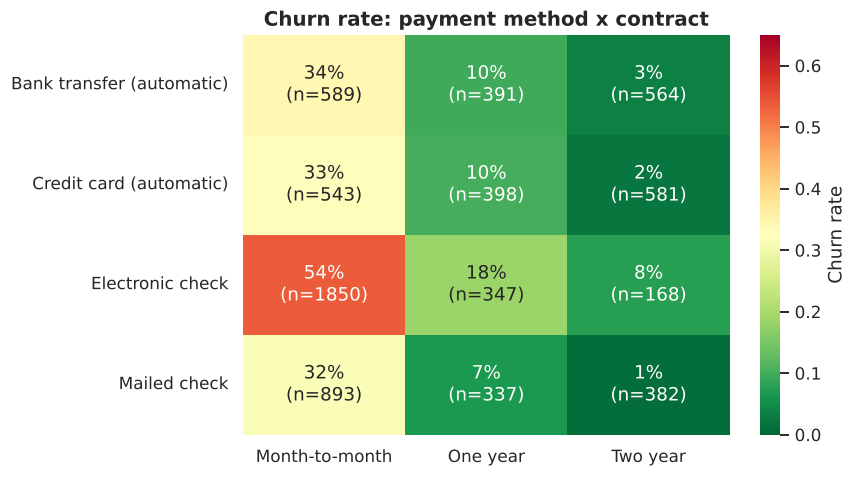

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
masked_heatmap("PaymentMethod", "Contract", ax, "Churn rate: payment method x contract")
plt.tight_layout(); plt.savefig("images/07_payment_contract_heatmap.png"); plt.show()

### Ranking the riskiest segments
Segments defined by contract, service tier and payment method, with at least 100 customers each.

In [17]:
seg = (df.groupby(["Contract", "Service Tier", "PaymentMethod"])["Churned"]
         .agg(Customers="size", Churners="sum", Churn_Rate="mean").reset_index())
seg = seg[seg["Customers"] >= 100].copy()
seg["Share_of_All_Churners"] = seg["Churners"] / n_churned
seg.sort_values("Churn_Rate", ascending=False).head(8).reset_index(drop=True).style.format(
    {"Churn_Rate": "{:.1%}", "Share_of_All_Churners": "{:.1%}"})

,Contract,Service Tier,PaymentMethod,Customers,Churners,Churn_Rate,Share_of_All_Churners
0,Month-to-month,"Fiber optic, no tech support",Electronic check,1138,716,62.9%,38.3%
1,Month-to-month,"Fiber optic, no tech support",Mailed check,164,87,53.0%,4.7%
2,Month-to-month,"Fiber optic, no tech support",Bank transfer (automatic),260,127,48.8%,6.8%
3,Month-to-month,"DSL, no tech support",Electronic check,365,162,44.4%,8.7%
4,Month-to-month,"Fiber optic, no tech support",Credit card (automatic),234,103,44.0%,5.5%
5,Month-to-month,"Fiber optic, tech support",Electronic check,169,73,43.2%,3.9%
6,Month-to-month,"DSL, no tech support",Mailed check,262,89,34.0%,4.8%
7,Month-to-month,"DSL, tech support",Electronic check,109,30,27.5%,1.6%


### The priority segment: month-to-month, fiber optic, no tech support

In [18]:
priority = (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "No")
p = df[priority]
p_churn = p["Churned"].sum()
p_mrr = p.loc[p["Churned"] == 1, "MonthlyCharges"].sum()

print(f"Customers in segment      : {len(p):,} ({len(p)/n_customers:.1%} of all customers)")
print(f"Segment churn rate        : {p['Churned'].mean():.1%} (baseline {baseline:.1%})")
print(f"Churners                  : {p_churn:,} ({p_churn/n_churned:.1%} of all churners)")
print(f"Monthly revenue lost      : ${p_mrr:,.0f} ({p_mrr/mrr_lost:.1%} of all revenue lost to churn)")

# comparison group: same contract and internet type, but WITH tech support
cmp = df[(df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "Yes")]
saved = len(p) * (p["Churned"].mean() - cmp["Churned"].mean())
print(f"\nSame contract + fiber, WITH tech support: {len(cmp):,} customers, churn {cmp['Churned'].mean():.1%}")
print(f"Illustrative: if the priority segment churned like that group, about {saved:,.0f} fewer customers "
      f"would leave ({saved/n_churned:.1%} of all churners).")
print("This is a correlation, not proof. Test any retention offer with an A/B experiment.")

Customers in segment      : 1,796 (25.5% of all customers)
Segment churn rate        : 57.5% (baseline 26.5%)
Churners                  : 1,033 (55.3% of all churners)
Monthly revenue lost      : $88,166 (63.4% of all revenue lost to churn)

Same contract + fiber, WITH tech support: 332 customers, churn 38.9%
Illustrative: if the priority segment churned like that group, about 335 fewer customers would leave (17.9% of all churners).
This is a correlation, not proof. Test any retention offer with an A/B experiment.


In [19]:
extra = {
    "Month-to-month + fiber + electronic check": (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic") & (df["PaymentMethod"] == "Electronic check"),
    "Fiber optic, no tech support (any contract)": (df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "No"),
    "Fiber optic, tech support (any contract)": (df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "Yes"),
    "1-2 year contract + automatic payment": (df["Contract"] != "Month-to-month") & df["PaymentMethod"].str.contains("automatic"),
}
pd.DataFrame([{"Segment": k, "Customers": int(m.sum()), "Churn_Rate": df.loc[m, "Churned"].mean()} for k, m in extra.items()]
             ).style.format({"Churn_Rate": "{:.1%}"})

,Segment,Customers,Churn_Rate
0,Month-to-month + fiber + electronic check,1307,60.4%
1,"Fiber optic, no tech support (any contract)",2230,49.4%
2,"Fiber optic, tech support (any contract)",866,22.6%
3,1-2 year contract + automatic payment,1934,5.7%


## 9. Executive takeaways

**1. One in four customers churns, and it hits revenue harder than headcount.**
The baseline churn rate is **26.5% (1,869 of 7,043 customers)**. Churners paid more than loyal customers (**$74.44 vs $61.27 per month**), so they represent **$139k of $456k monthly revenue (30.5%)**. Churners also leave early: median tenure is **10 months vs 38** for retained customers.

**2. Contract type is the biggest lever.**
Month-to-month customers churn at **42.7%**, versus **11.3% on one-year** and **2.8% on two-year** contracts. Month-to-month customers are 55% of the base but **88.6% of all churners**.

**3. The first year is the danger zone.**
Customers with 0-12 months of tenure churn at **47.4%**, versus **6.6%** for those with 61-72 months, and **55.5% of all churners (1,037) left within their first year**. The retention curves show it clearly: only **70.3% of month-to-month customers are still active at 12 months and 58.6% at 24 months**, compared with 99.1% and 97.8% on one-year contracts.

**4. Fiber optic customers without tech support are the core problem.**
Fiber churns at **41.9% vs 19.0% for DSL**. Within fiber, customers **without tech support churn at 49.4% (2,230 customers) versus 22.6% with it (866 customers)**. A similar pattern holds for online security (41.8% without vs 14.6% with).

**5. Electronic check payers are far more likely to leave.**
Electronic check customers churn at **45.3%**, versus **15.2-19.1%** for every other payment method. They are 33.6% of customers but **57.3% of churners**. The gap persists inside month-to-month contracts (**53.7% vs about 32-34%**). Customers on a 1-2 year contract who also pay automatically churn at just **5.7%**.

**6. One segment explains most of the loss.**
Customers on **month-to-month, fiber optic, no tech support** are **25.5% of the base (1,796 customers) but 55.3% of all churners (1,033)** and **63.4% of revenue lost to churn ($88k per month)**. Their churn rate is **57.5%**. Adding electronic check pushes the rate to **60.4%** (1,307 customers).

**7. Price and demographics.**
Customers paying $75-95 per month churn at **36.3%**, versus **10.9%** for those paying $35 or less. **Senior citizens churn at 41.7% vs 23.6%**, and customers without a partner (33.0% vs 19.7%) or dependents (31.3% vs 15.5%) churn more. Gender makes no difference (26.9% vs 26.2%).

### Strategic retention recommendations
1. **Move month-to-month customers onto longer contracts.** Offer a discount or perk for a 12-month commitment, and time it between months 3 and 10, before most customers leave.
2. **Build a first-year onboarding program.** Proactive check-ins and service-quality monitoring in the first 12 months target the period that produces more than half of all churn.
3. **Bundle tech support and online security for fiber customers.** Free trials or discounted bundles for the priority segment. In the data, comparable fiber customers with support churn roughly 19 points less (57.5% vs 38.9%), worth about 335 retained customers if the link is even partly causal, so run an A/B test first.
4. **Convert electronic check payers to automatic payment** with a small credit. Automatic payers on longer contracts churn at under 6%.
5. **Investigate fiber service quality and pricing.** A 41.9% churn rate against 19.0% for DSL points to an experience or value problem, not only a support gap.
6. **Offer simpler support options to senior customers**, who churn at nearly twice the rate of others.

### Limitations
- The data is a snapshot: `Churn` marks customers who left recently, and tenure is months with the company. Cohorts are tenure bands, not calendar sign-up cohorts.
- Contract type is the customer's current contract. Some customers may have switched contracts during their tenure.
- Findings show associations, not causes. Customers choosing tech support may also be more engaged, so retention offers should be tested.
- Segment sizes shrink as filters are combined, so rates for small segments are less reliable (cells under 30 customers are hidden).